# Inspect recordings and mine hard-negative crops
Review one raw recording at a time, inspect a saved model's causal left/right probabilities, and export chosen false-alarm intervals as single-session negative recordings. Additional models can be overlaid for comparison; only `SELECTION_MODEL` generates the candidate list.

Inputs live in `hard_negative_mining/source_recordings/`; reviewed CSV/label pairs go to `hard_negative_mining/crops/` for manual copying into a dataset's `train_data/`. Open with the repository `.venv` kernel and run cells in order.

In [1]:
from pathlib import Path
import importlib
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis import hard_negative_mining as mining
importlib.reload(mining)
torch.set_num_threads(2)

SOURCE_DIR = ROOT / 'temp'
INPUT_DIR = ROOT / 'hard_negative_mining/source_recordings'
OUTPUT_DIR = ROOT / 'hard_negative_mining/crops'

# Add/remove models here. Thresholds are manual inspection settings, not retuned exports.
MODELS = {
    'feature_0910d8(102)': {
        'checkpoint': ROOT / 'testing_checkpoints/lstm64_features/0910d8(102)feat/best.pt',
        'left_threshold': 0.65, 'right_threshold': 0.51,
    },
    'raw_0910d8(52)': {
        'checkpoint': ROOT / 'testing_checkpoints/0910d8(52)/best.pt',
        'left_threshold': 0.60, 'right_threshold': 0.60,
    },
}
SELECTION_MODEL = 'raw_0910d8(52)'
RESET_AT_SEGMENTS = False  # Continuous through the whole file; always reset between files.
assert SELECTION_MODEL in MODELS

## 1. Stage and inventory inputs
Copy raw CSVs and existing sparse `.txt` sidecars from `SOURCE_DIR`. Identical copies are reused, so rerunning this cell is safe. The recording inventory includes both the ordinary ZR single-tap recordings and the one-minute Miguel mining recordings. A minute recorded as one session stays one continuous session during inspection.

In [19]:
staged = mining.stage_recordings(SOURCE_DIR, INPUT_DIR)
inventory = mining.recording_inventory(INPUT_DIR)
display(inventory)
models = {name: mining.load_mining_model(spec['checkpoint']) for name, spec in MODELS.items()}
print('Staged:', len(staged), '| models:', ', '.join(models))

,file,user,action,frames,seconds,sample_rate_hz,sessions,annotated_events
0,imu_Miguel_negative_mining_20261009_164938.csv,Miguel,negative_mining,6002,60.02,100.0,1,0
1,imu_Miguel_negative_mining_20261009_165059.csv,Miguel,negative_mining,5999,59.99,100.0,1,0
2,imu_Miguel_negative_mining_20261009_172016.csv,Miguel,negative_mining,6003,60.03,100.0,1,0
3,imu_Miguel_negative_mining_20261009_172339.csv,Miguel,negative_mining,6001,60.01,100.0,1,0
4,imu_Miguel_negative_mining_20261009_172541.csv,Miguel,negative_mining,6001,60.01,100.0,1,0
5,imu_Miguel_negative_mining_20261009_172653.csv,Miguel,negative_mining,6001,60.01,100.0,1,0
6,imu_Miguel_negative_mining_20261009_172814.csv,Miguel,negative_mining,5998,59.98,100.0,1,0
7,imu_Miguel_negative_mining_20261009_172921.csv,Miguel,negative_mining,5999,59.99,100.0,1,0
8,imu_Miguel_negative_mining_20261009_173235.csv,Miguel,negative_mining,5999,59.99,100.0,1,0
9,imu_Miguel_negative_mining_20261009_173341.csv,Miguel,negative_mining,5999,59.99,100.0,1,0


Staged: 12 | models: feature_0910d8(102), raw_0910d8(52)


## 2. Select a recording and run one model
Set `RECORDING_INDEX` from the inventory, or set `RECORDING_FILE` to its filename. To inspect another recording, rerun from this cell onward. Inference uses each checkpoint's high-pass setting and frozen feature normalization. It runs over every original frame, including the entire one-minute session.

In [107]:
RECORDING_INDEX = 11
# RECORDING_FILE = 'imu_Miguel_negative_mining_20261009_164938.csv'  # e.g. 'imu_Miguel_negative_mining_20261009_164938.csv'
RECORDING_FILE = None
filename = RECORDING_FILE or inventory.iloc[RECORDING_INDEX]['file']
recording = mining.load_recording(INPUT_DIR / filename)
traces = {SELECTION_MODEL: mining.predict_recording(recording, models[SELECTION_MODEL], RESET_AT_SEGMENTS)}
print(filename, '|', len(recording.data), 'frames |', f'{recording.fs:g} Hz',
      '|', len(recording.segments), 'session(s) |', len(recording.events), 'annotated double taps')

imu_Miguel_negative_mining_20261009_173627.csv | 5998 frames | 100 Hz | 1 session(s) | 0 annotated double taps


## 3. Tune candidate and crop settings
A candidate starts when either side reaches its threshold. The detector waits `LOOKAHEAD_FRAMES`, picks the largest qualifying probability, and shares one cooldown across both sides. `ANCHOR` chooses the first crossing, selected probability peak, or alarm emission frame. For every crossing without lookahead, use `LOOKAHEAD_FRAMES = 0`; adjust `REFRACTORY_FRAMES` to control repeated candidates.

The marked hard interval is inclusive: `[anchor - CORE_BEFORE_FRAMES, anchor + CORE_AFTER_FRAMES]`. Defaults **40/10 frames** mean **−400/+100 ms at 100 Hz**, or 51 samples. Export context defaults **200/99** mean exactly **300 frames / 3 s**; both context settings can be `None` to export only the marked interval. For about 5 s use **200/299**. Convert milliseconds with `round(ms * recording.fs / 1000)` if the sample rate differs.

The training loader edge-pads short sessions and takes only the first `window_samples` frames of long negative sessions. `training_retains_core` tells you whether the marked hard interval survives. Crop context slides within the source session near its boundaries and never joins separate sessions. These detections are **review candidates**; inspect the IMU before choosing which are genuinely negatives.

In [108]:
# Edit MODELS above for side thresholds, then rerun this cell; traces need not be recomputed.
LOOKAHEAD_FRAMES = 0
REFRACTORY_FRAMES = 50
ANCHOR = 'peak'  # 'crossing', 'peak', or 'alarm'
CORE_BEFORE_FRAMES = 40
CORE_AFTER_FRAMES = 10
CONTEXT_BEFORE_FRAMES = 200  # None for no extra preceding context
CONTEXT_AFTER_FRAMES = 99  # None for no extra trailing context
TRAINING_WINDOW_FRAMES = models[SELECTION_MODEL].window_samples
thresholds = {name: (spec['left_threshold'], spec['right_threshold']) for name, spec in MODELS.items()}
candidates = mining.find_candidates(
    recording, traces[SELECTION_MODEL], SELECTION_MODEL, *thresholds[SELECTION_MODEL],
    lookahead_frames=LOOKAHEAD_FRAMES, refractory_frames=REFRACTORY_FRAMES, anchor=ANCHOR,
    before_frames=CORE_BEFORE_FRAMES, after_frames=CORE_AFTER_FRAMES,
    context_before_frames=CONTEXT_BEFORE_FRAMES, context_after_frames=CONTEXT_AFTER_FRAMES,
    training_window_frames=TRAINING_WINDOW_FRAMES, reset_at_segments=RESET_AT_SEGMENTS,
)
REVIEW_COLUMNS = ['candidate_id', 'side', 'probability', 'anchor_frame', 'anchor_seconds',
                  'crossing_frame', 'peak_frame', 'alarm_frame', 'segment_index',
                  'crop_start_frame', 'crop_end_frame', 'crop_frames', 'crop_seconds',
                  'anchor_in_crop', 'training_retains_core', 'annotated_events_in_crop']
display(candidates[REVIEW_COLUMNS])
print(len(candidates), 'candidates from', SELECTION_MODEL, '| core offsets (ms):',
      -CORE_BEFORE_FRAMES * 1000 / recording.fs, CORE_AFTER_FRAMES * 1000 / recording.fs)

,candidate_id,side,probability,anchor_frame,anchor_seconds,crossing_frame,peak_frame,alarm_frame,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,anchor_in_crop,training_retains_core,annotated_events_in_crop
0,0,right,0.600659,196,1.96,196,196,196,1,0,300,300,3.0,196,True,0
1,1,left,0.685912,1393,13.93,1393,1393,1393,1,1193,1493,300,3.0,200,True,0
2,2,left,0.671831,1984,19.84,1984,1984,1984,1,1784,2084,300,3.0,200,True,0
3,3,right,0.663376,2716,27.16,2716,2716,2716,1,2516,2816,300,3.0,200,True,0
4,4,right,0.626191,2844,28.44,2844,2844,2844,1,2644,2944,300,3.0,200,True,0
5,5,left,0.603891,3102,31.02,3102,3102,3102,1,2902,3202,300,3.0,200,True,0
6,6,left,0.621250,3495,34.95,3495,3495,3495,1,3295,3595,300,3.0,200,True,0
7,7,right,0.627169,4519,45.19,4519,4519,4519,1,4319,4619,300,3.0,200,True,0
8,8,left,0.643452,4830,48.30,4830,4830,4830,1,4630,4930,300,3.0,200,True,0
9,9,left,0.681534,5018,50.18,5018,5018,5018,1,4818,5118,300,3.0,200,True,0


11 candidates from raw_0910d8(52) | core offsets (ms): -400.0 100.0


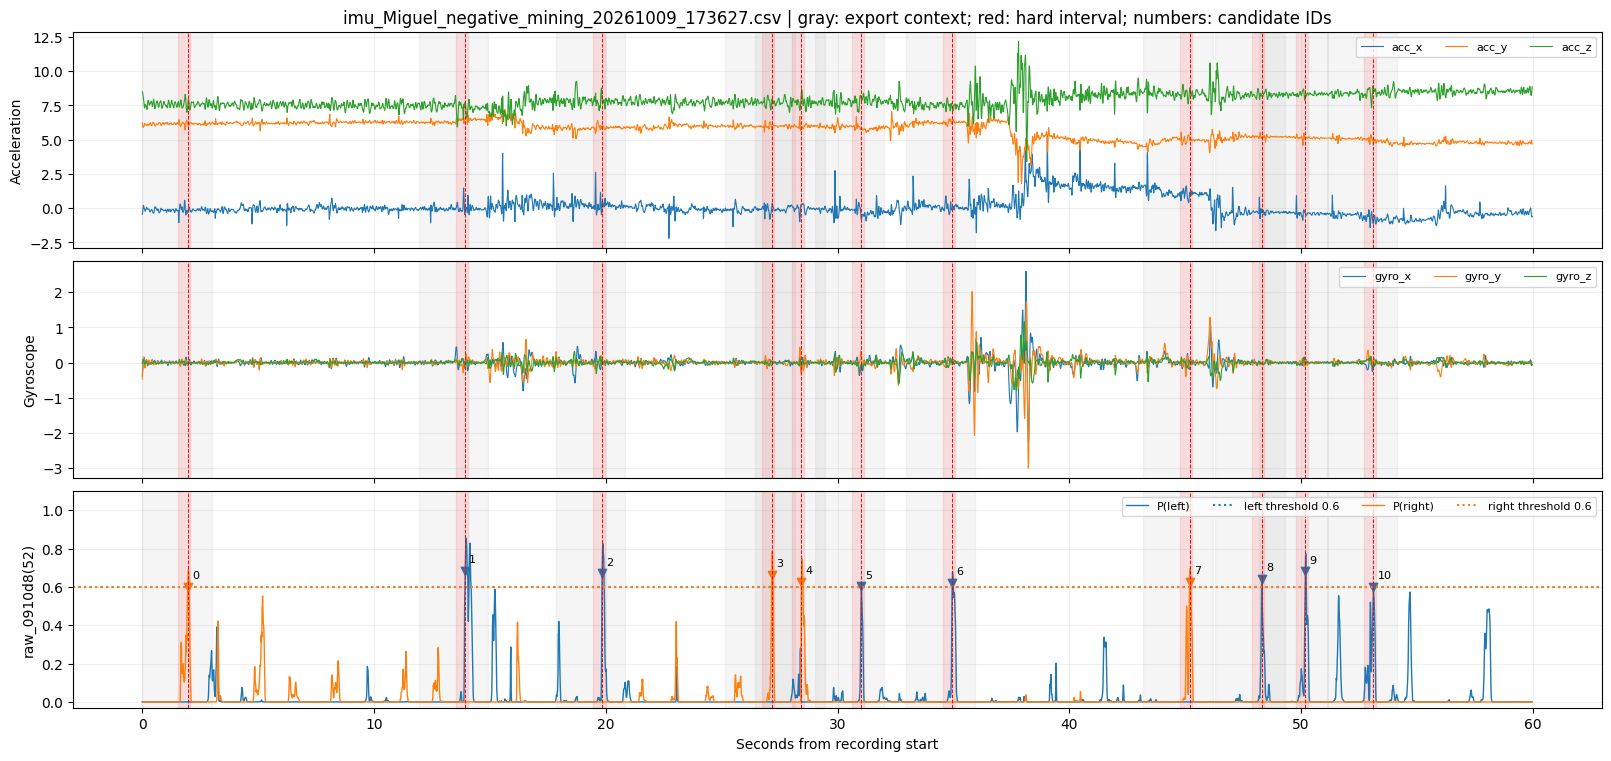

In [109]:
# Whole-recording overview. Gray spans are exported context; red spans are the short core.
mining.plot_recording(recording, {SELECTION_MODEL: traces[SELECTION_MODEL]}, thresholds, candidates)
plt.show()

## 4. Zoom into an individual candidate or arbitrary interval
Change `PREVIEW_CANDIDATE_ID` and rerun for each candidate. Set it to `None` to inspect an arbitrary time range using `VIEW_START_SECONDS` / `VIEW_END_SECONDS`. The surrounding view is separate from the exported crop size.

,candidate_id,side,probability,anchor_frame,anchor_seconds,crossing_frame,peak_frame,alarm_frame,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,anchor_in_crop,training_retains_core,annotated_events_in_crop
0,0,right,0.600659,196,1.96,196,196,196,1,0,300,300,3.0,196,True,0


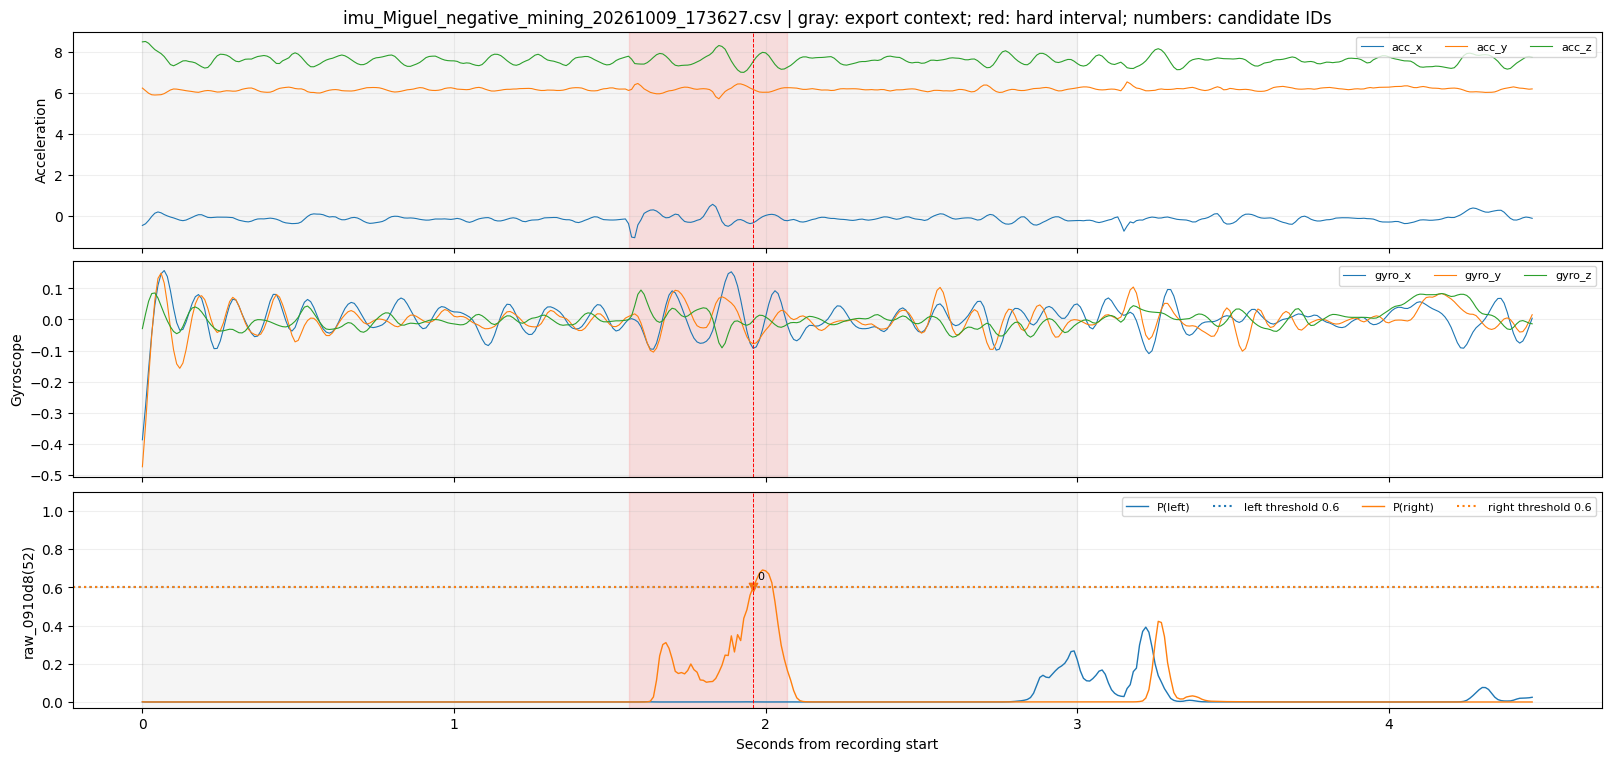

In [110]:
PREVIEW_CANDIDATE_ID = int(candidates.candidate_id.iloc[0]) if len(candidates) else None
VIEW_BEFORE_FRAMES = 250
VIEW_AFTER_FRAMES = 250
VIEW_START_SECONDS = 0.0
VIEW_END_SECONDS = 5.0
if PREVIEW_CANDIDATE_ID is None:
    view_start = round(VIEW_START_SECONDS * recording.fs)
    view_end = round(VIEW_END_SECONDS * recording.fs)
    preview_rows = candidates[(candidates.anchor_frame >= view_start) & (candidates.anchor_frame < view_end)]
else:
    preview_rows = candidates[candidates.candidate_id == PREVIEW_CANDIDATE_ID]
    assert len(preview_rows) == 1, 'Pick an existing candidate ID'
    center = int(preview_rows.anchor_frame.iloc[0])
    view_start, view_end = center - VIEW_BEFORE_FRAMES, center + VIEW_AFTER_FRAMES + 1
display(preview_rows[REVIEW_COLUMNS])
mining.plot_recording(recording, {SELECTION_MODEL: traces[SELECTION_MODEL]}, thresholds,
                      preview_rows, view_start, view_end)
plt.show()

## 5. Compare multiple models on the same recording
Choose any subset of `MODELS`. Each checkpoint applies its own preprocessing to the same raw frames. This section plots their outputs on the same time axis and uses the current zoom; it does not change the candidate list or selection model.

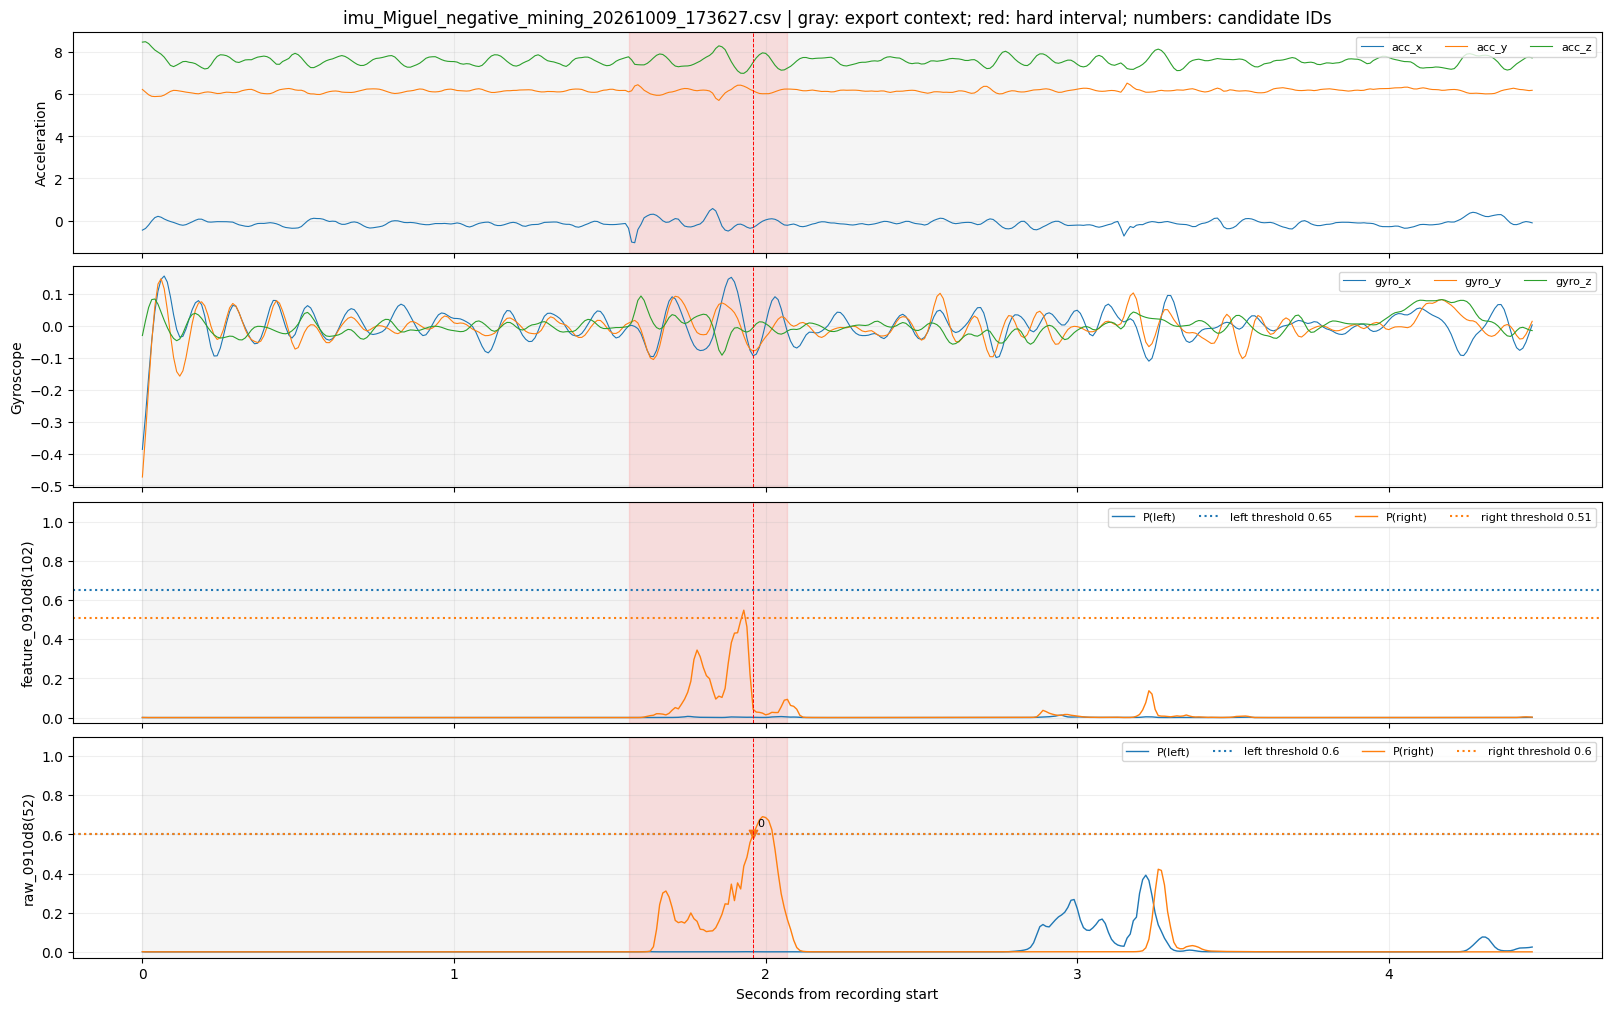

In [111]:
COMPARISON_MODELS = list(MODELS)
for name in COMPARISON_MODELS:
    if name not in traces:
        traces[name] = mining.predict_recording(recording, models[name], RESET_AT_SEGMENTS)
mining.plot_recording(recording, {name: traces[name] for name in COMPARISON_MODELS},
                      thresholds, preview_rows, view_start, view_end)
plt.show()

## 6. Choose reviewed negatives and preview exports
Enter the candidate IDs you want to keep. For example, `REVIEWED_IDS = [0, 3]`. The list starts empty. Review overlapping crops before selecting redundant examples. If thresholds, anchor, or recording change, regenerate candidates and choose IDs from the new table.

,candidate_id,side,probability,anchor_frame,anchor_seconds,crossing_frame,peak_frame,alarm_frame,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,anchor_in_crop,training_retains_core,annotated_events_in_crop
0,0,right,0.600659,196,1.96,196,196,196,1,0,300,300,3.0,196,True,0
1,1,left,0.685912,1393,13.93,1393,1393,1393,1,1193,1493,300,3.0,200,True,0
2,2,left,0.671831,1984,19.84,1984,1984,1984,1,1784,2084,300,3.0,200,True,0
3,3,right,0.663376,2716,27.16,2716,2716,2716,1,2516,2816,300,3.0,200,True,0
4,4,right,0.626191,2844,28.44,2844,2844,2844,1,2644,2944,300,3.0,200,True,0
5,5,left,0.603891,3102,31.02,3102,3102,3102,1,2902,3202,300,3.0,200,True,0
6,6,left,0.621250,3495,34.95,3495,3495,3495,1,3295,3595,300,3.0,200,True,0
7,7,right,0.627169,4519,45.19,4519,4519,4519,1,4319,4619,300,3.0,200,True,0
8,8,left,0.643452,4830,48.30,4830,4830,4830,1,4630,4930,300,3.0,200,True,0
9,9,left,0.681534,5018,50.18,5018,5018,5018,1,4818,5118,300,3.0,200,True,0


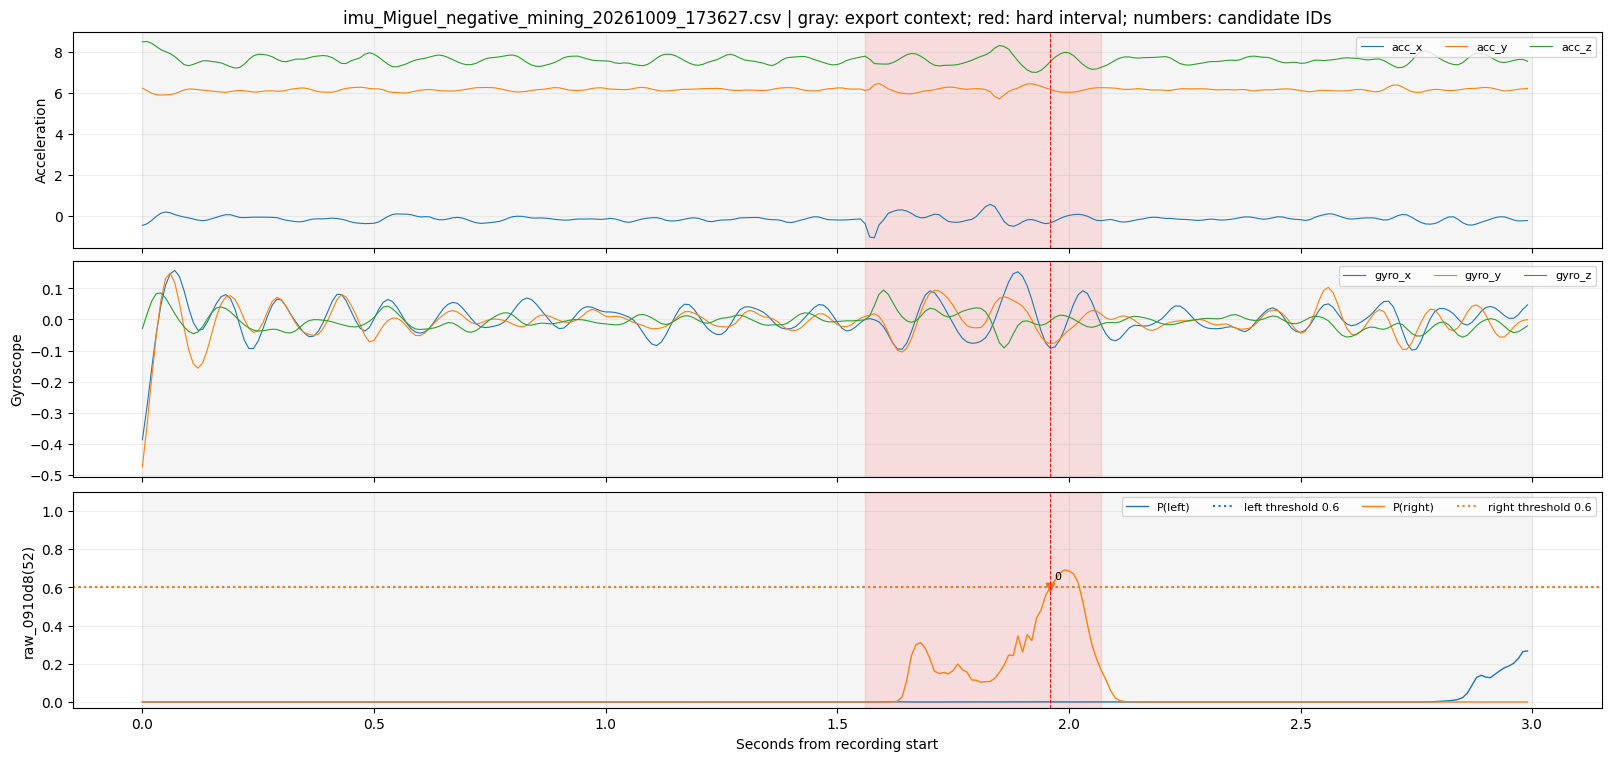

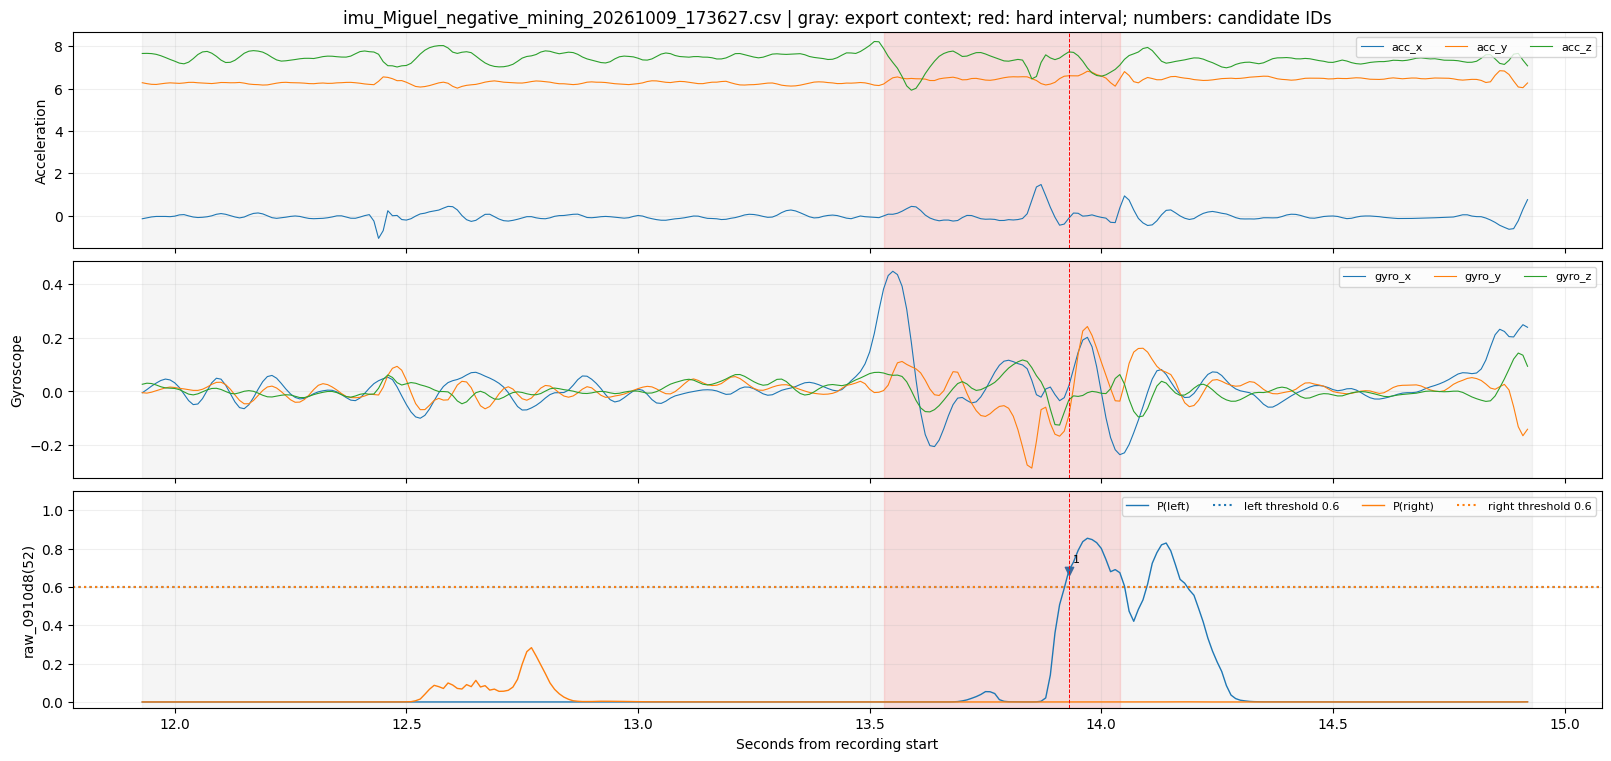

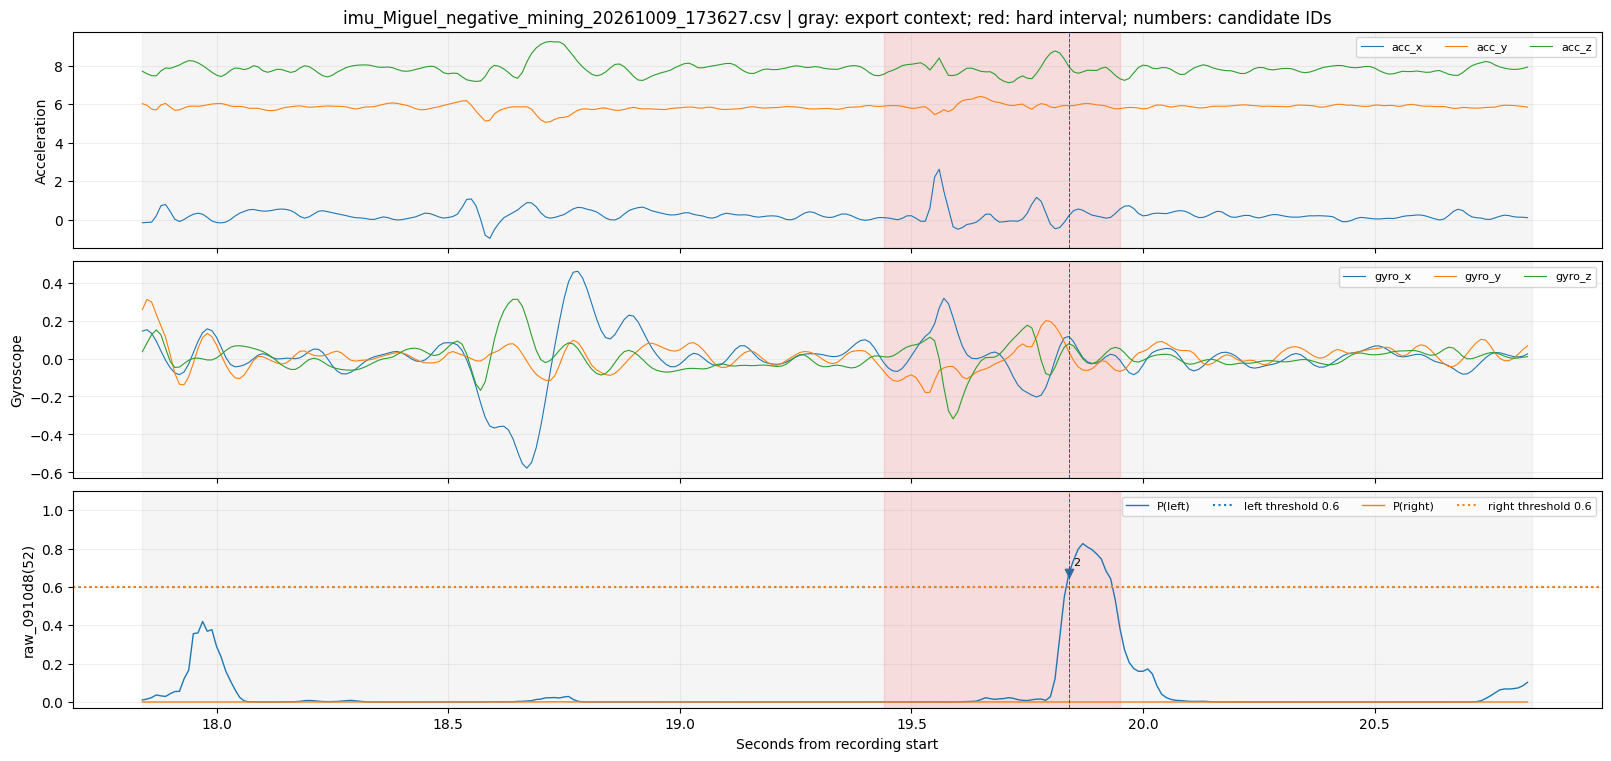

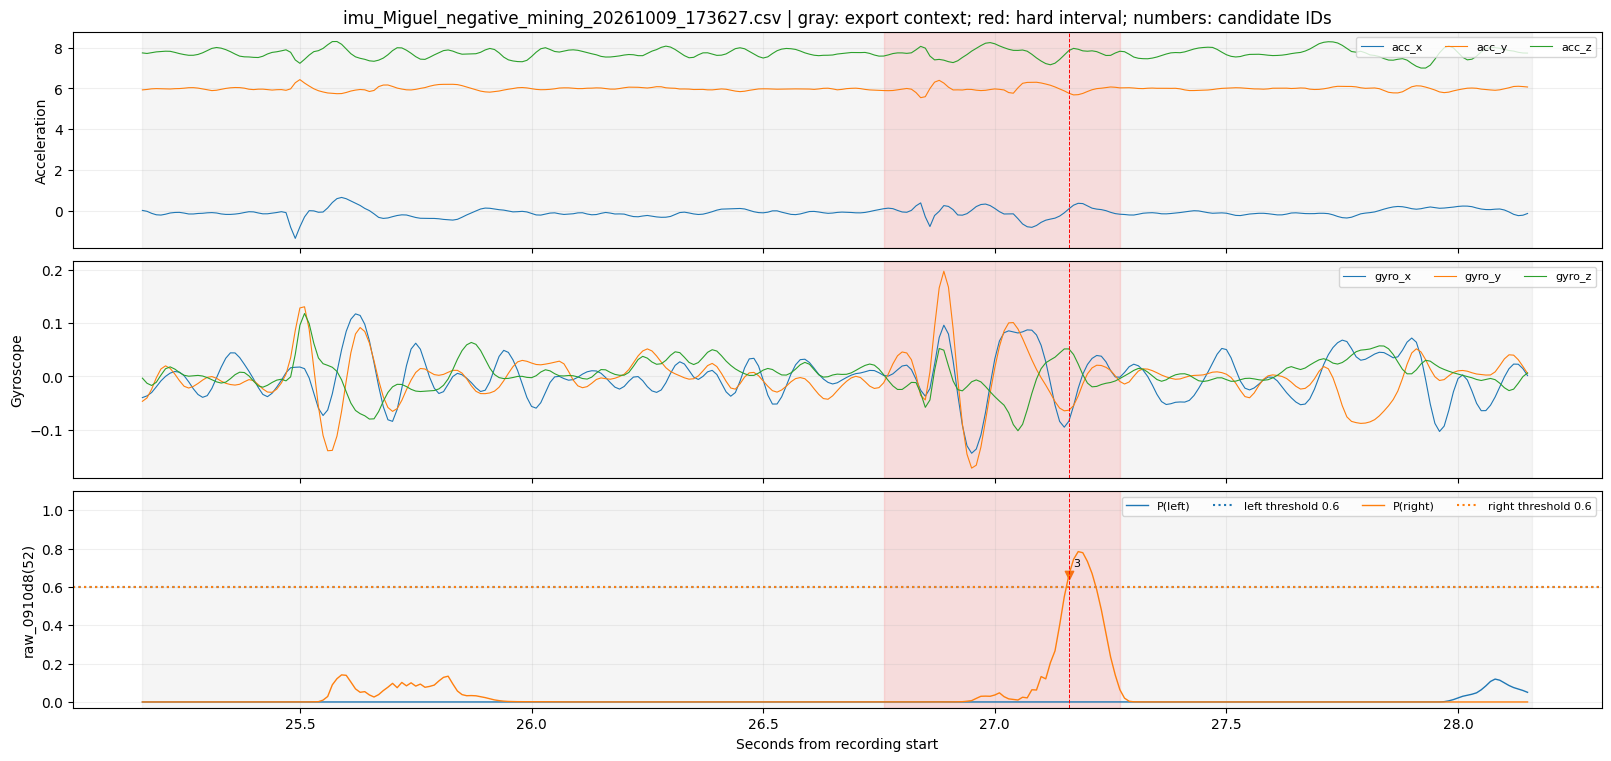

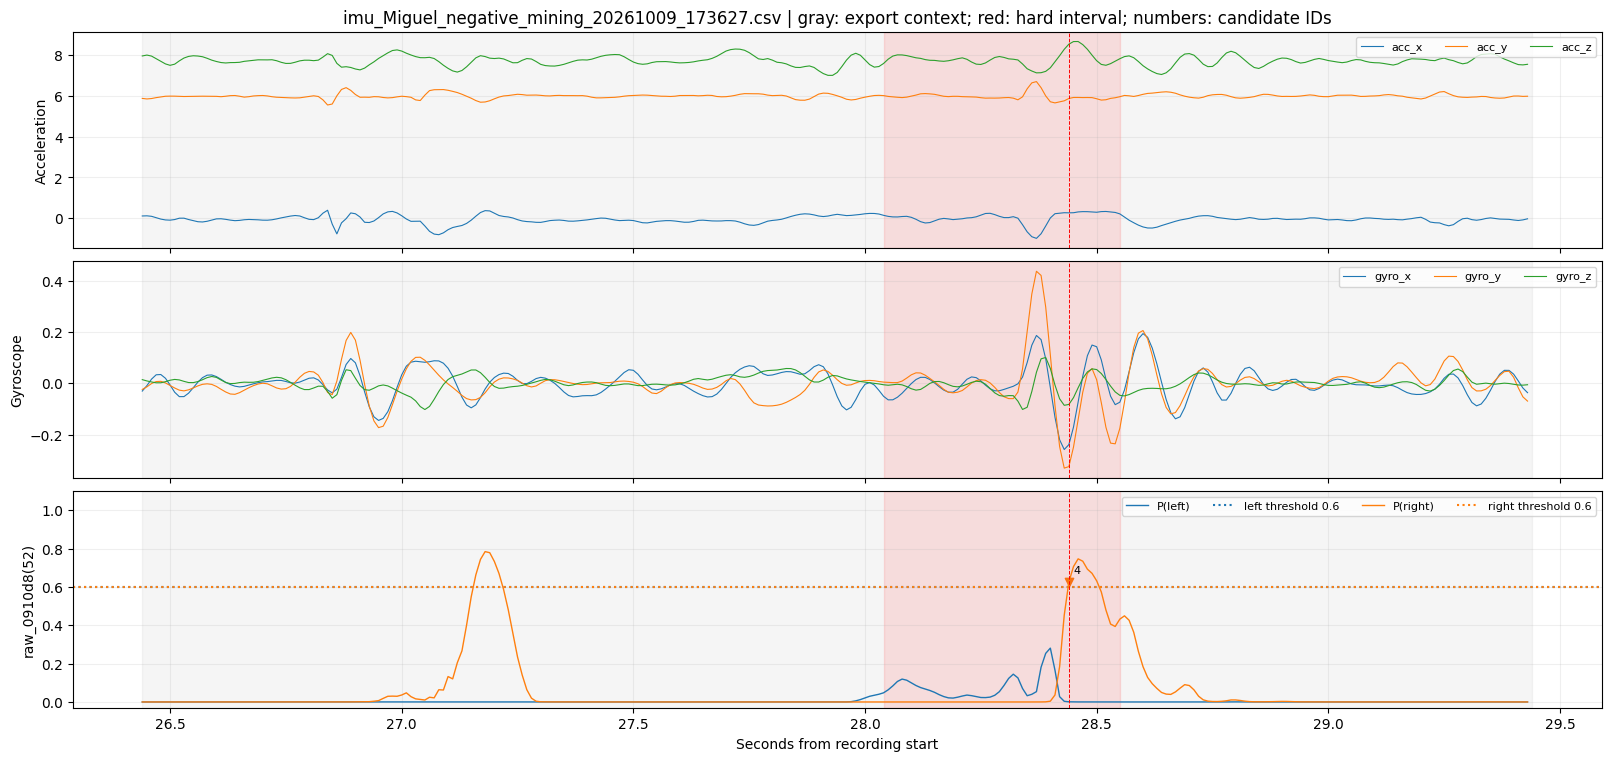

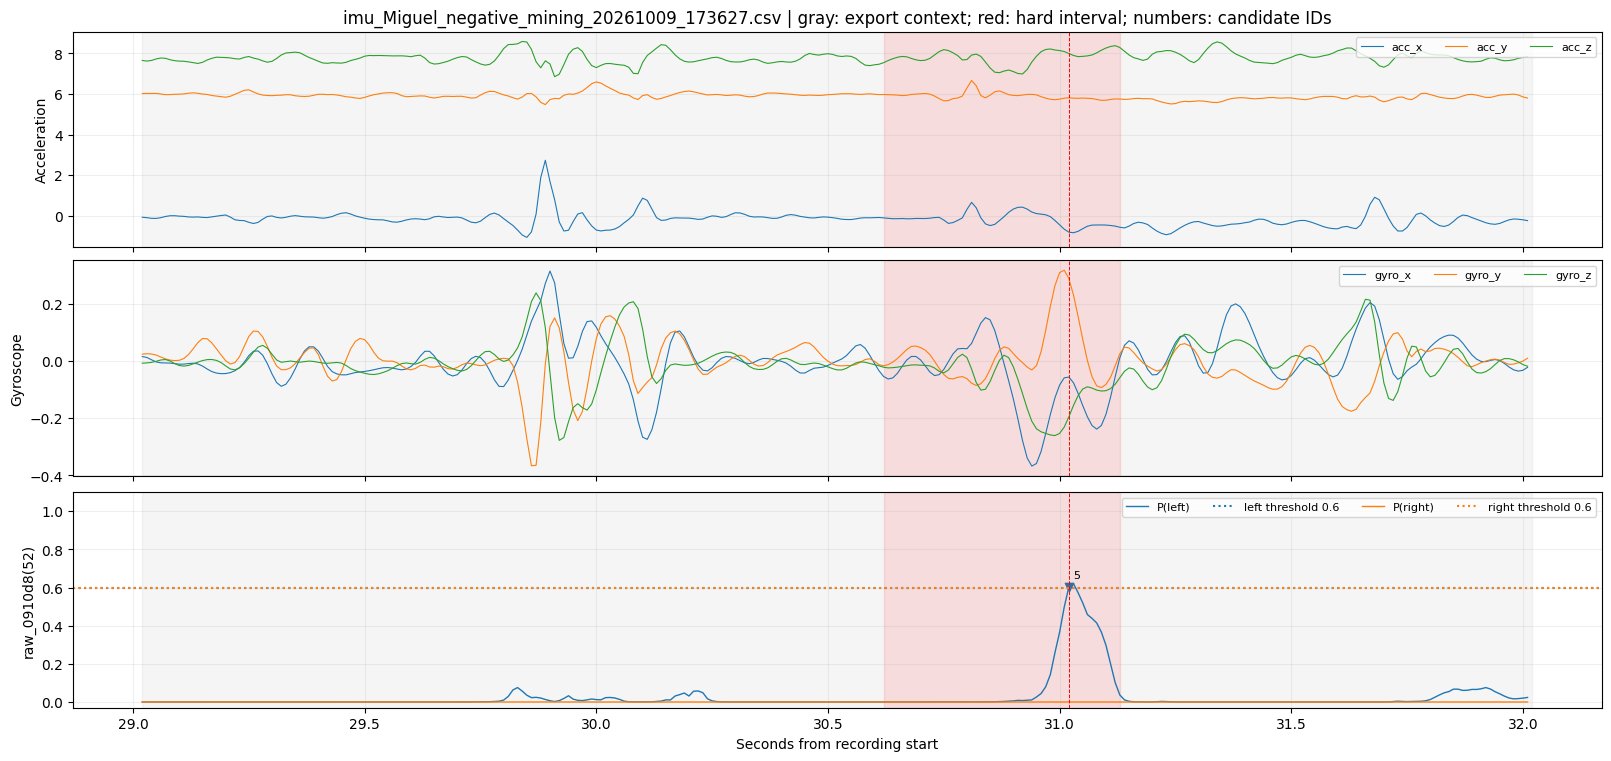

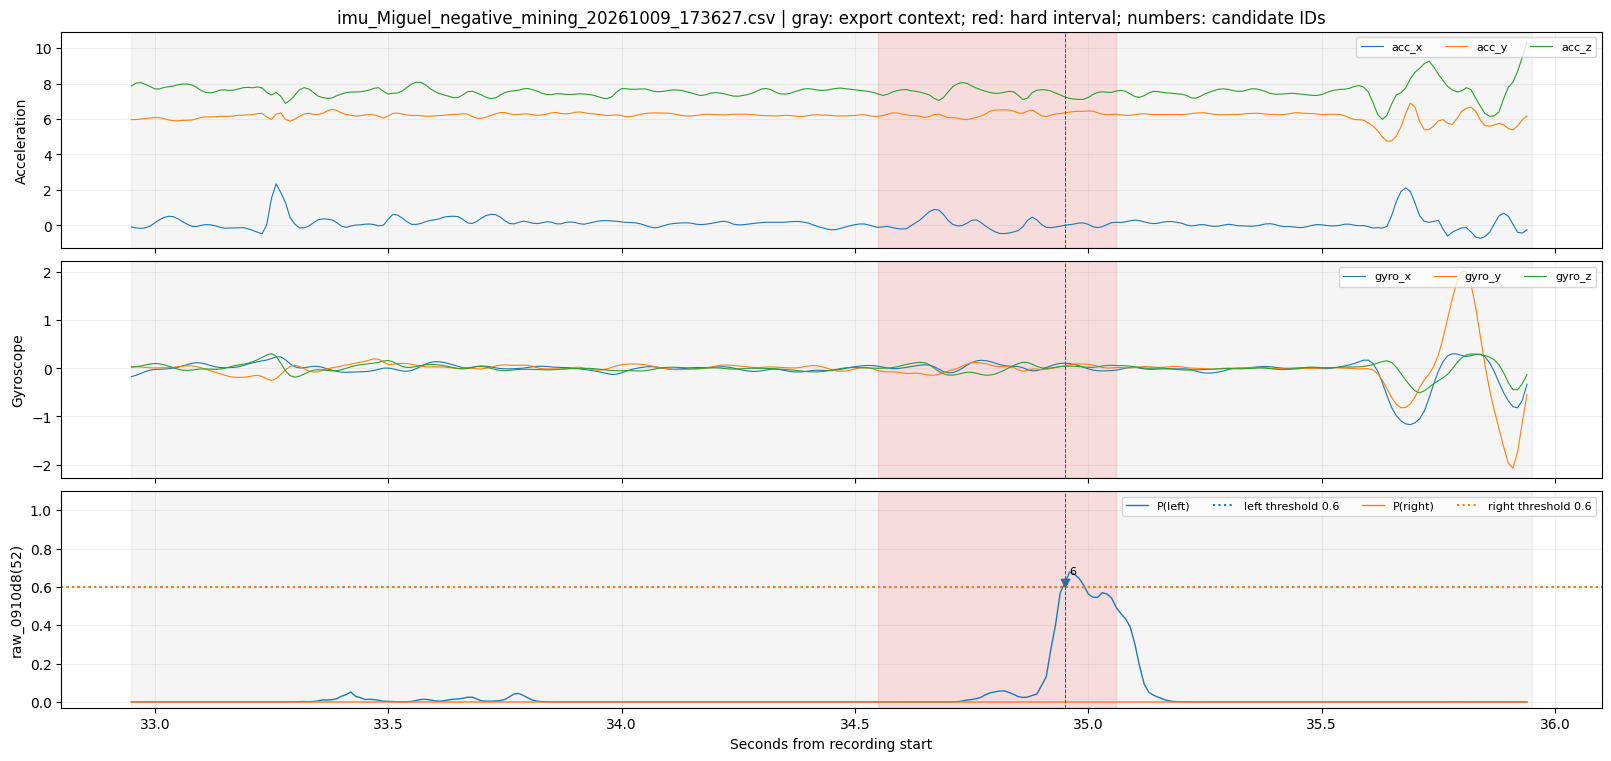

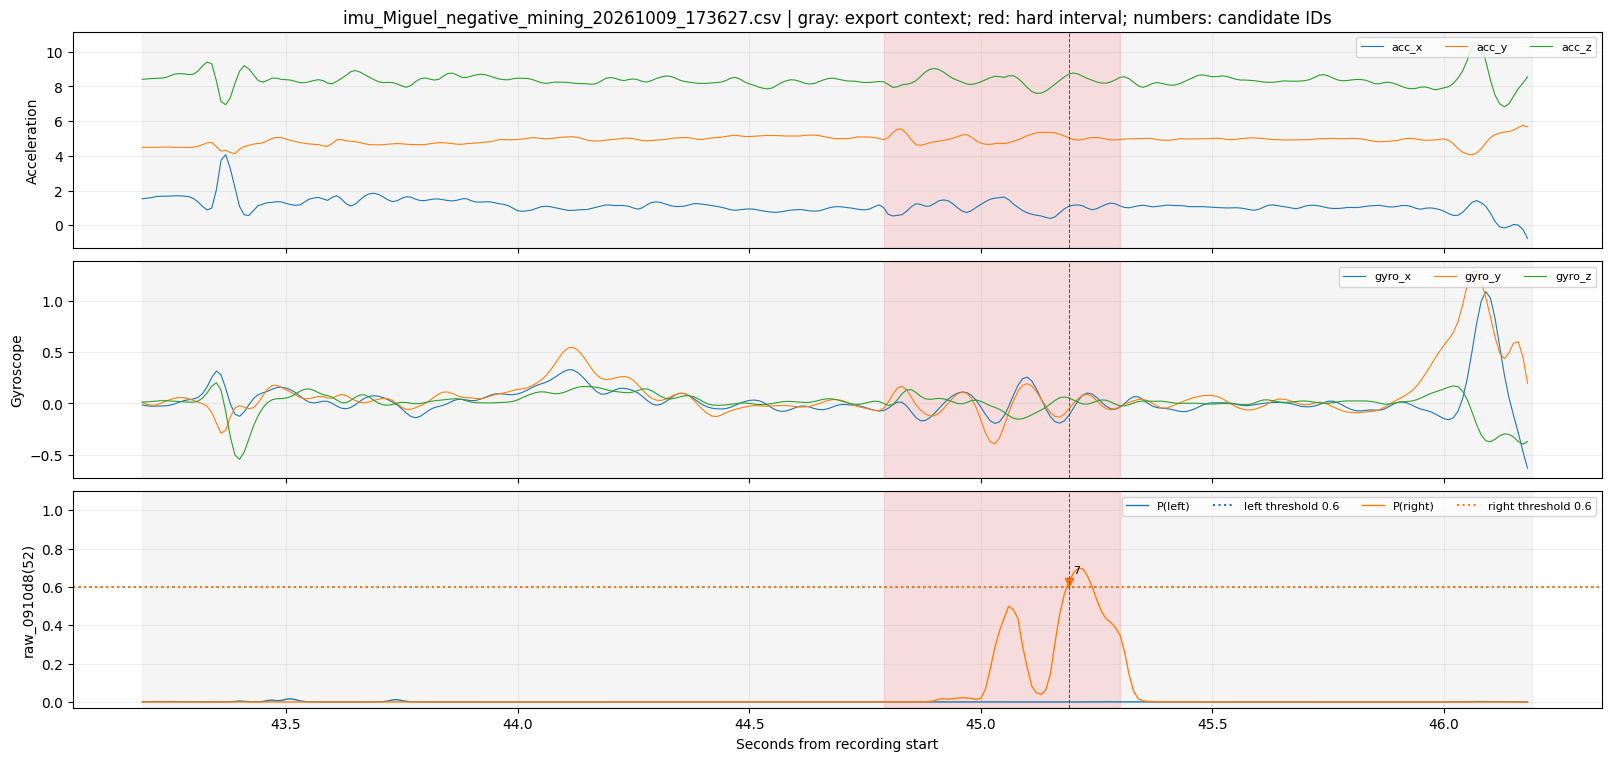

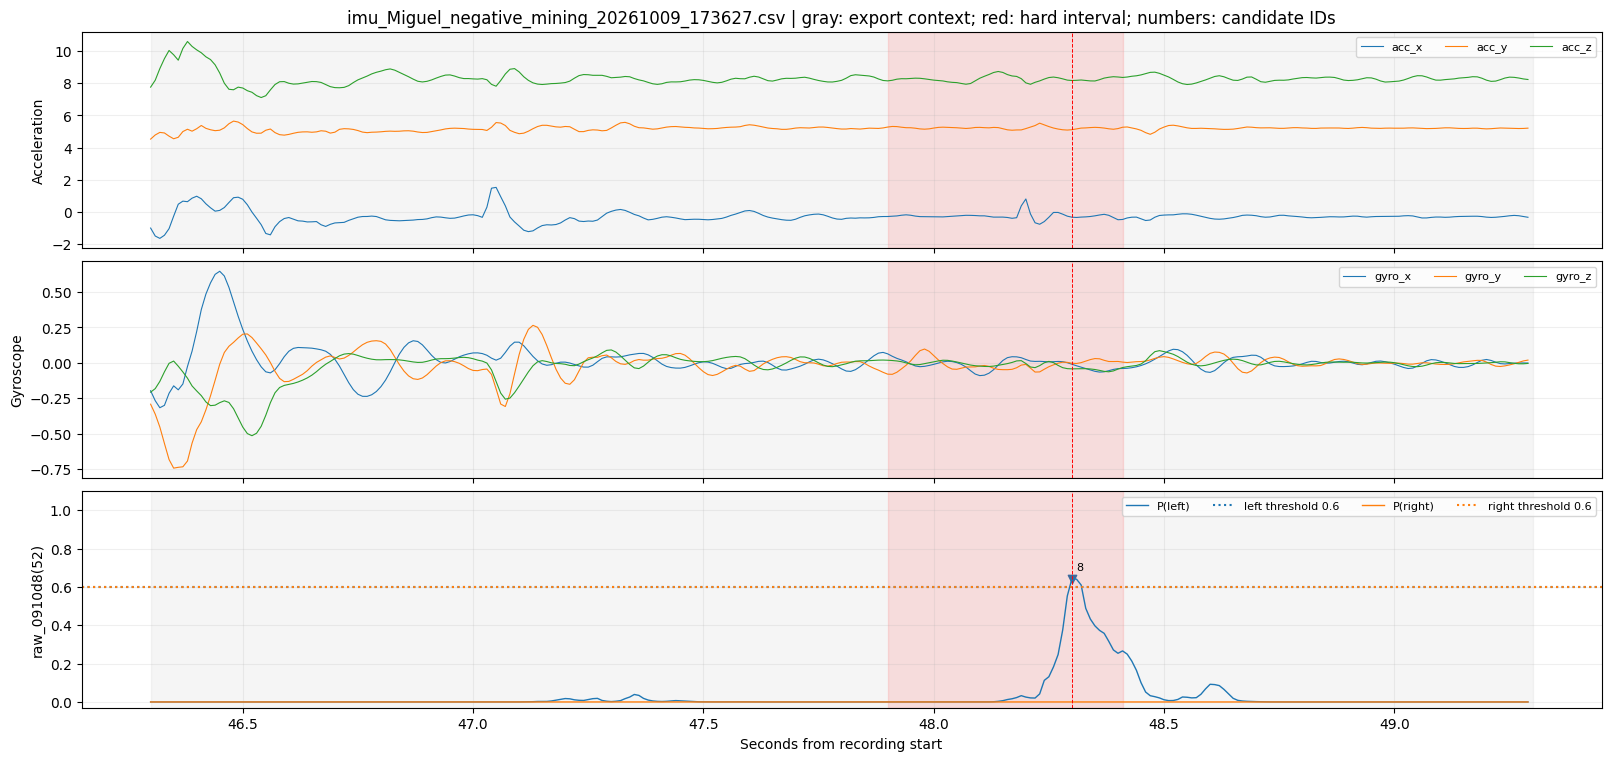

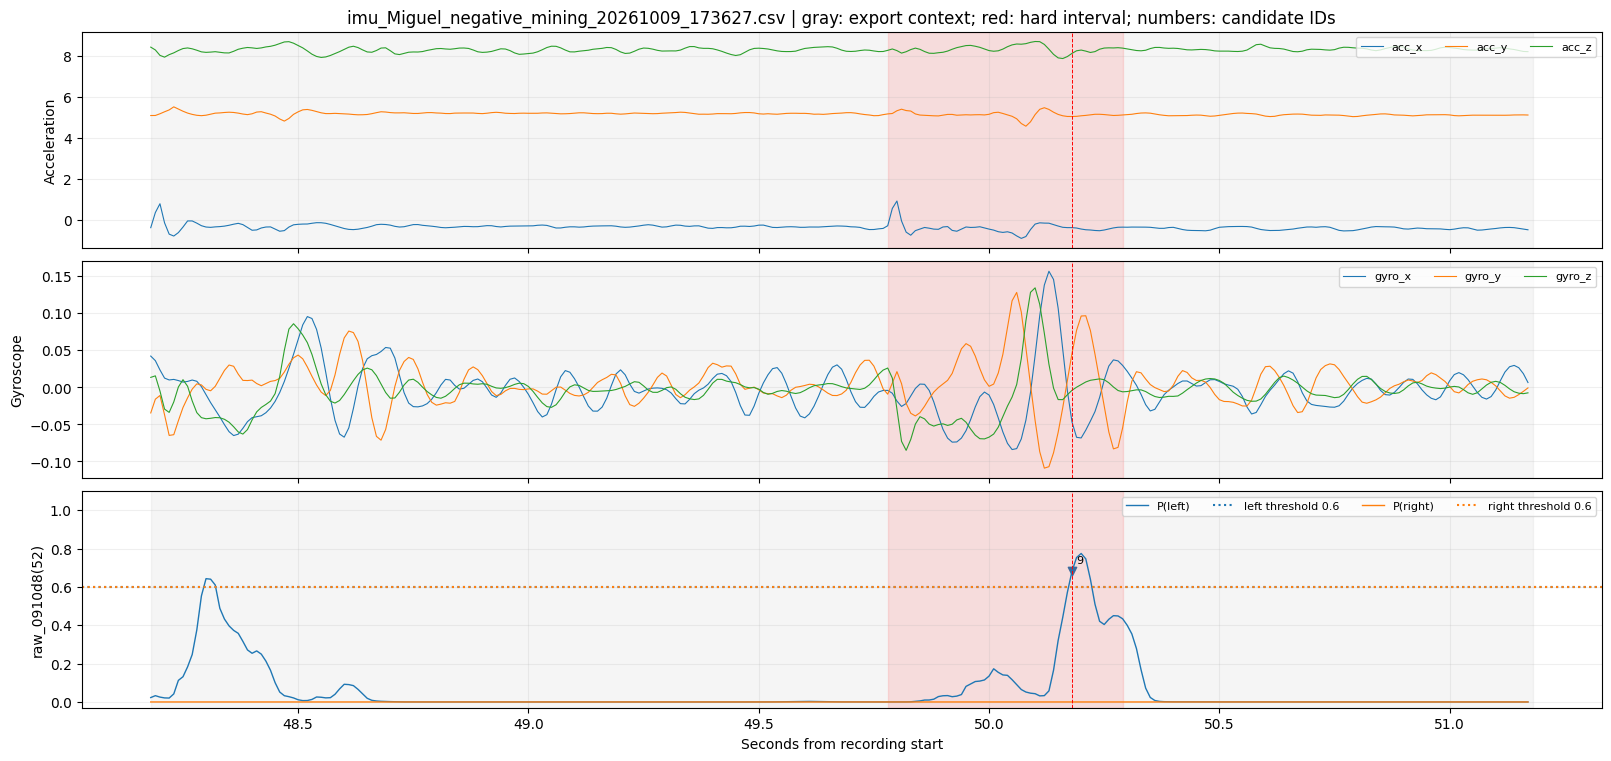

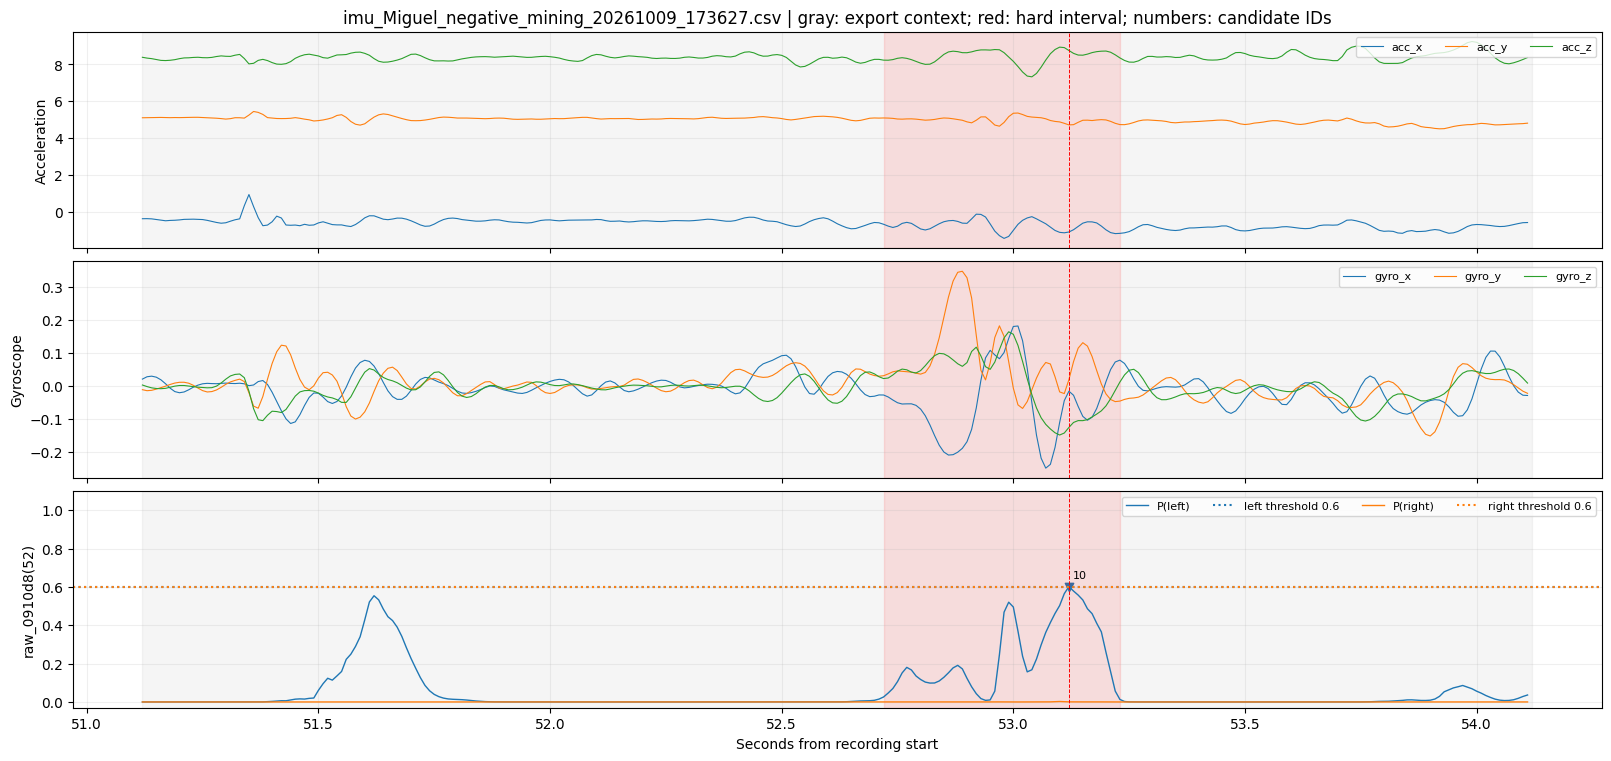

In [113]:
REVIEWED_IDS = range(11)
assert len(REVIEWED_IDS) == len(set(REVIEWED_IDS)), 'Duplicate candidate IDs'
assert set(REVIEWED_IDS) <= set(candidates.candidate_id), 'Unknown candidate ID; refresh your selection'
reviewed = candidates[candidates.candidate_id.isin(REVIEWED_IDS)].copy()
display(reviewed[REVIEW_COLUMNS])
for _, row in reviewed.iterrows():
    mining.plot_recording(recording, {SELECTION_MODEL: traces[SELECTION_MODEL]}, thresholds,
                          reviewed[reviewed.candidate_id == row.candidate_id],
                          int(row.crop_start_frame), int(row.crop_end_frame))
    plt.show()

## 7. Export selected raw CSV/label pairs
Run after reviewing the selection above. Every crop has a rebased timestamp, `segment_index=1`, raw sensor values, and an explicit empty `.txt` event label. Its `.mining.json` preserves the original bounds, source/checkpoint hashes, thresholds and detector settings. Identical reruns reuse outputs; conflicting filenames are reported. Copy only chosen **CSV + `.txt` pairs** into the desired dataset's `train_data/` manually.

In [114]:
exports = mining.export_candidates(recording, reviewed, models[SELECTION_MODEL],
                                   OUTPUT_DIR, TRAINING_WINDOW_FRAMES)
display(exports)
print(len(exports), 'selected crop(s) in', OUTPUT_DIR)

,candidate_id,csv,label,provenance,frames,seconds,anchor_in_crop,status
0,0,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,196,exported
1,1,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
2,2,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
3,3,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
4,4,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
5,5,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
6,6,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
7,7,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
8,8,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported
9,9,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,/home/miguel/TapRecognition/hard_negative_mini...,300,3.0,200,exported


11 selected crop(s) in /home/miguel/TapRecognition/hard_negative_mining/crops


## 8. Inspect an exported crop exactly as training sees it
This uses the real `RecordedIMUDataset`, including high-pass reset at the crop start and padding/truncation to the model's training length. Recurrent/CNN state starts fresh. The scores can differ from the full-recording trace because the preceding history has changed; use this view to check that the cropped example is still useful.

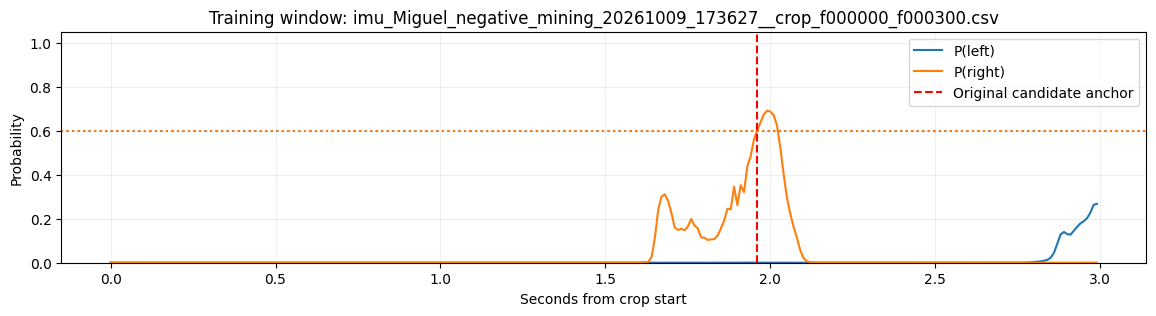

In [115]:
from tap_recognition.dataset import RecordedIMUDataset
EXPORTED_CROP_INDEX = 0
if exports.empty:
    print('Select and export a candidate to inspect its training window.')
else:
    export_row = exports.iloc[EXPORTED_CROP_INDEX]
    loaded_model = models[SELECTION_MODEL]
    training_ds = RecordedIMUDataset(OUTPUT_DIR, window_samples=TRAINING_WINDOW_FRAMES,
                                     highpass=loaded_model.highpass, csv_paths=[export_row.csv])
    assert len(training_ds) == 1 and int(training_ds[0]['window_label']) == 0
    assert (training_ds[0]['frame_labels'][:, 0] == 1).all()
    with torch.inference_mode():
        logits, _ = loaded_model.model(training_ds[0]['imu'].unsqueeze(0))
        crop_probs = logits[0].softmax(-1).numpy()
    t = np.arange(len(crop_probs)) / recording.fs
    fig, ax = plt.subplots(figsize=(14, 3))
    for cls, side, color, threshold in ((1, 'left', 'tab:blue', thresholds[SELECTION_MODEL][0]),
                                         (2, 'right', 'tab:orange', thresholds[SELECTION_MODEL][1])):
        ax.plot(t, crop_probs[:, cls], color=color, label=f'P({side})')
        ax.axhline(threshold, color=color, ls=':')
    ax.axvline(export_row.anchor_in_crop / recording.fs, color='red', ls='--', label='Original candidate anchor')
    ax.set(xlabel='Seconds from crop start', ylabel='Probability', ylim=(0, 1.05),
           title=f'Training window: {Path(export_row.csv).name}')
    ax.legend()
    ax.grid(alpha=.2)
    plt.show()